<a href="https://colab.research.google.com/github/tristansalazar/MachineLearning-/blob/main/Unidad%204/Practica_1_CNN_Diagnostico_Medico_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Instituto Tecnológico de Durango
## Tecnológico Nacional de México

### Machine Learning y Deep Learning

Unidad 5

Practica 1: **Implementación de una Red Neuronal Convolucional (CNN) para Diagnóstico Médico**

Facilitador: *Dr. José Gabriel Rodríguez Rivas*

Alumno:

Fernandez Varela Alan Eduardo

Salazar Rueda Diego Tristán

Zapata Lopez Victor Hugo

## Red Neuronal Convolucional para diagnóstico médico

**Objetivo:**

Implementar una red neuronal convolucional (CNN) que clasifique radiografías de tórax en NORMAL o PNEUMONIA, usando el dataset Chest X-Ray Images (Pneumonia), pasando por todo el proceso: preparar los datos, construir el modelo, entrenarlo y evaluarlo.

El dataset tiene tres carpetas (`train`, `val` y `test`) y dentro de cada una las carpetas `NORMAL` y `PNEUMONIA`.

## Cargar librerías

In [5]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import VGG16
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt
import numpy as np

## Montar Google Drive en Colab

In [6]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Descargar el dataset

El dataset Chest X-Ray Images (Pneumonia) se descarga directo de Kaggle con la librería kagglehub.

In [7]:
import kagglehub
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
print(path)

Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
/kaggle/input/chest-xray-pneumonia


## Definir estructura de directorios

In [8]:
base_dir = path + '/chest_xray/'
train_dir = base_dir + 'train/'
val_dir = base_dir + 'val/'
test_dir = base_dir + 'test/'

## Parte 1 - Cargar imágenes y mostrarlas

Se muestran 5 imágenes al azar de cada categoría para comprobar que el dataset se lee bien.

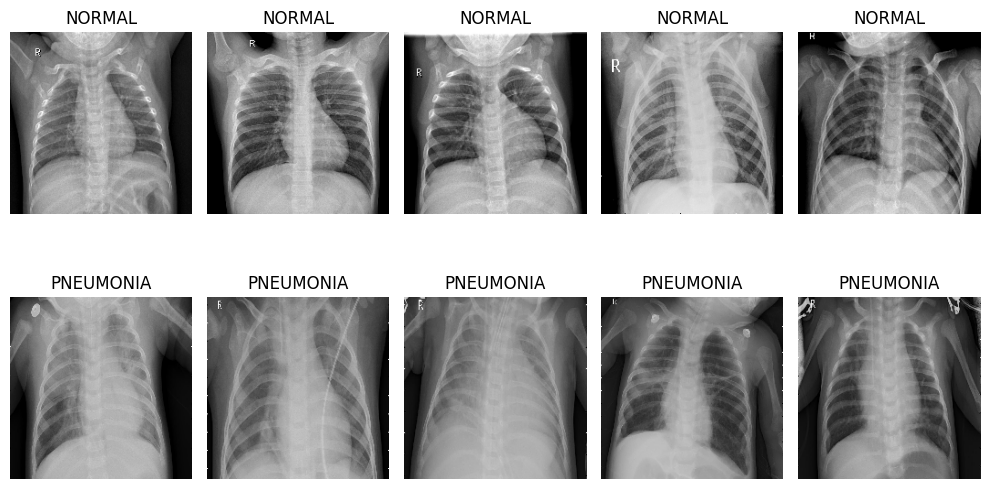

In [9]:
import os
import random
from tensorflow.keras.preprocessing.image import load_img, img_to_array

categories = ["NORMAL", "PNEUMONIA"]
num_images = 5

plt.figure(figsize=(10, 6))
img_index = 1

for category in categories:
    path = os.path.join(train_dir, category)
    images = os.listdir(path)
    selected_images = random.sample(images, num_images)

    for img_name in selected_images:
        img_path = os.path.join(path, img_name)
        img = load_img(img_path, target_size=(200, 200))
        plt.subplot(2, num_images, img_index)
        plt.imshow(img)
        plt.title(category)
        plt.axis("off")
        img_index += 1

plt.tight_layout()
plt.show()

## Parte 2 - Preparar generadores de datos (ImageDataGenerator)

- Todas las imágenes se redimensionan a 150x150 y los píxeles se normalizan entre 0 y 1.
- Al conjunto de entrenamiento se le aplica aumento de datos (rotaciones, desplazamientos, zoom y volteo) para que la red no memorice las imágenes.
- A validación y prueba no se les aplica aumento, solo la normalización.

In [10]:
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest'
)

test_val_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(150, 150),
    batch_size=32,
    class_mode='binary'
)

val_generator = test_val_datagen.flow_from_directory(
    val_dir,
    target_size=(150, 150),
    batch_size=32,
    class_mode='binary'
)

test_generator = test_val_datagen.flow_from_directory(
    test_dir,
    target_size=(150, 150),
    batch_size=32,
    class_mode='binary',
    shuffle=False
)

Found 5216 images belonging to 2 classes.
Found 16 images belonging to 2 classes.
Found 624 images belonging to 2 classes.


## Parte 3 - Construcción del modelo CNN con Keras

El modelo tiene 3 bloques de convolución con MaxPooling (32, 64 y 128 filtros), después se aplana con Flatten, pasa por una capa densa de 128 neuronas con Dropout y termina en una neurona con sigmoid (0 = NORMAL, 1 = PNEUMONIA).

In [11]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

model = Sequential()

model.add(Conv2D(32, (3, 3), activation='relu', input_shape=(150, 150, 3)))
model.add(MaxPooling2D(2, 2))

model.add(Conv2D(64, (3, 3), activation='relu'))
model.add(MaxPooling2D(2, 2))

model.add(Conv2D(128, (3, 3), activation='relu'))
model.add(MaxPooling2D(2, 2))

model.add(Flatten())

model.add(Dense(128, activation='relu'))
model.add(Dropout(0.5))

model.add(Dense(1, activation='sigmoid'))

model.compile(
    loss='binary_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,735,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,828,481 (18.42 MB)

 Trainable params: 4,828,481 (18.42 MB)

 Non-trainable params: 0 (0.00 B)

## Parte 4 - Entrenar la red neuronal (CNN)

Se usan dos callbacks:

- **EarlyStopping:** detiene el entrenamiento si `val_loss` no mejora en 3 épocas y recupera los mejores pesos.
- **ModelCheckpoint:** guarda en Drive el modelo cada vez que `val_loss` mejora.

In [12]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

checkpoint = ModelCheckpoint(
    "/content/drive/MyDrive/modelo_pneumonia_cnn.h5",
    monitor='val_loss',
    save_best_only=True,
    verbose=1
)

epochs = 10

history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=epochs,
    callbacks=[early_stop, checkpoint]
)

Epoch 1/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 875ms/step - accuracy: 0.7255 - loss: 0.5902
Epoch 1: val_loss improved from None to 0.66217, saving model to /content/drive/MyDrive/modelo_pneumonia_cnn.h5



Epoch 1: finished saving model to /content/drive/MyDrive/modelo_pneumonia_cnn.h5
163/163 ━━━━━━━━━━━━━━━━━━━━ 160s 903ms/step - accuracy: 0.7604 - loss: 0.5036 - val_accuracy: 0.6250 - val_loss: 0.6622
Epoch 2/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 686ms/step - accuracy: 0.8277 - loss: 0.3603
Epoch 2: val_loss did not improve from 0.66217
163/163 ━━━━━━━━━━━━━━━━━━━━ 112s 687ms/step - accuracy: 0.8378 - loss: 0.3520 - val_accuracy: 0.6250 - val_loss: 0.7501
Epoch 3/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 699ms/step - accuracy: 0.8744 - loss: 0.3025
Epoch 3: val_loss did not improve from 0.66217
163/163 ━━━━━━━━━━━━━━━━━━━━ 114s 701ms/step - accuracy: 0.8698 - loss: 0.3068 - val_accuracy: 0.6250 - val_loss: 0.7893
Epoch 4/10
163/163 ━━━━━━━━━━━━━━━━━━━━ 0s 699ms/step - accuracy: 0.8747 - loss: 0.2828
Epoch 4: val_loss did not improve from 0.66217
163/163 ━━━━━━━━━━━━━━━━━━━━ 114s 701ms/step - accuracy: 0.8725 - loss: 0.2848 - val_accuracy: 0.8125 - val_loss: 0.6722


### Gráficas de accuracy y loss

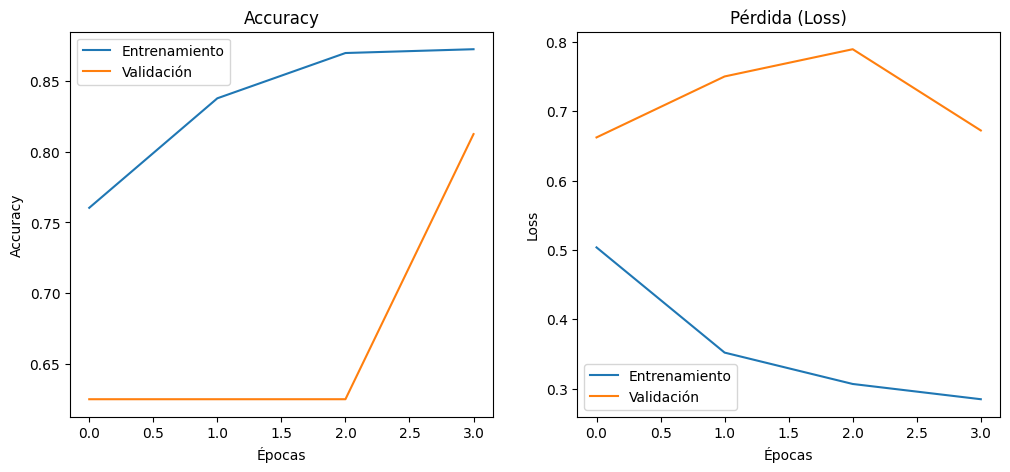

In [13]:
plt.figure(figsize=(12,5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label="Entrenamiento")
plt.plot(history.history['val_accuracy'], label="Validación")
plt.title("Accuracy")
plt.xlabel("Épocas")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label="Entrenamiento")
plt.plot(history.history['val_loss'], label="Validación")
plt.title("Pérdida (Loss)")
plt.xlabel("Épocas")
plt.ylabel("Loss")
plt.legend()

plt.show()

## Parte 5 - Evaluar el modelo y generar la matriz de confusión

Se evalúa el modelo con el conjunto de prueba (test), que son imágenes que la red nunca vio durante el entrenamiento.

In [14]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

test_loss, test_acc = model.evaluate(test_generator)
print("Loss en test:", test_loss)
print("Accuracy en test:", test_acc)

pred_probs = model.predict(test_generator)
pred_classes = (pred_probs > 0.5).astype(int).flatten()
true_classes = test_generator.classes
class_labels = list(test_generator.class_indices.keys())

20/20 ━━━━━━━━━━━━━━━━━━━━ 14s 537ms/step - accuracy: 0.7420 - loss: 0.4795
Loss en test: 0.4795062243938446
Accuracy en test: 0.7419871687889099
20/20 ━━━━━━━━━━━━━━━━━━━━ 9s 398ms/step


### Matriz de confusión

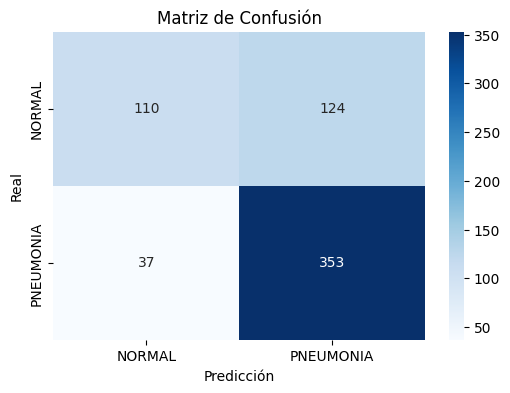

In [15]:
cm = confusion_matrix(true_classes, pred_classes)

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_labels,
            yticklabels=class_labels)
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.title("Matriz de Confusión")
plt.show()

### Reporte de clasificación

In [16]:
print("Reporte de Clasificación:\n")
print(classification_report(true_classes, pred_classes, target_names=class_labels))

Reporte de Clasificación:

              precision    recall  f1-score   support

      NORMAL       0.75      0.47      0.58       234
   PNEUMONIA       0.74      0.91      0.81       390

    accuracy                           0.74       624
   macro avg       0.74      0.69      0.70       624
weighted avg       0.74      0.74      0.73       624



### Imágenes mal clasificadas

Total de imágenes mal clasificadas: 161


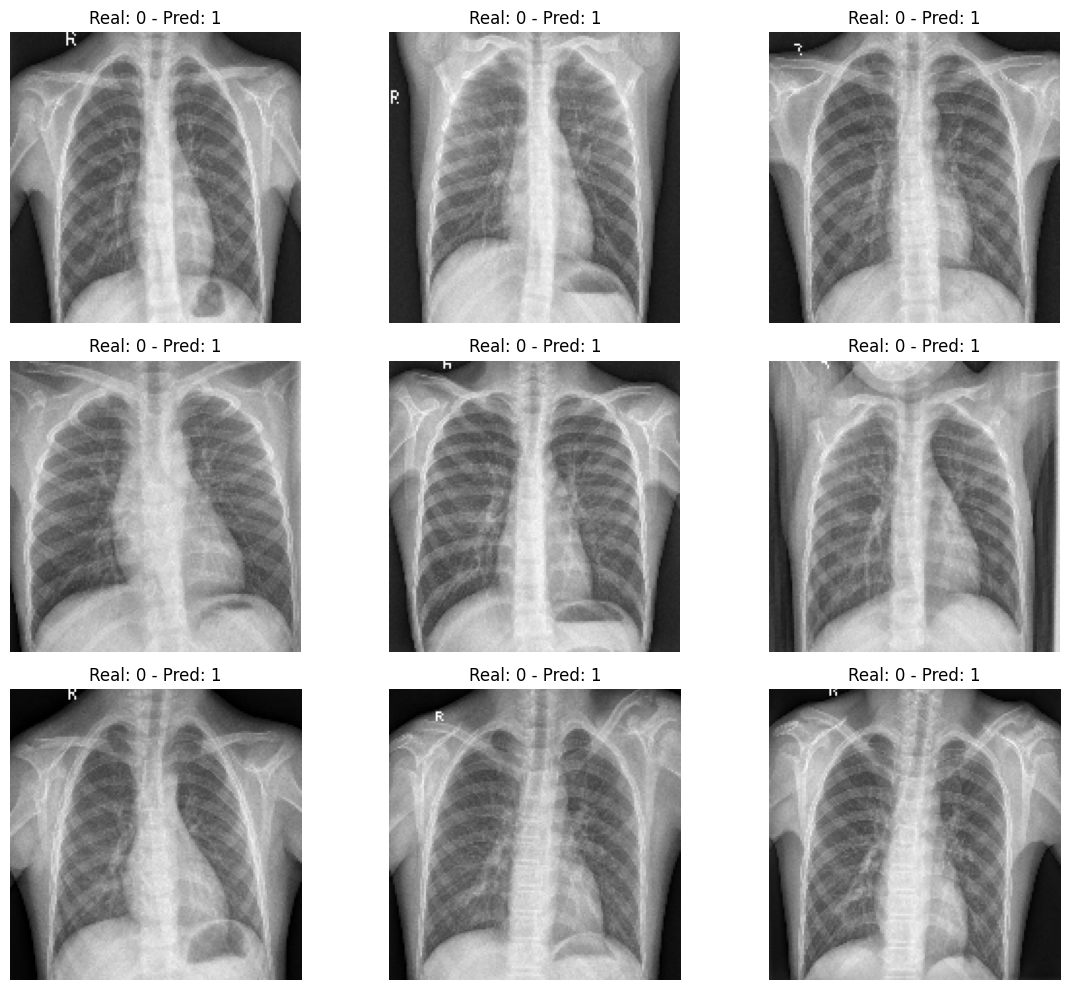

In [17]:
image_paths = test_generator.filepaths
misclassified_indices = np.where(true_classes != pred_classes)[0]

print(f"Total de imágenes mal clasificadas: {len(misclassified_indices)}")

plt.figure(figsize=(12, 10))

for i, idx in enumerate(misclassified_indices[:9]):
    img = load_img(image_paths[idx], target_size=(150, 150))
    plt.subplot(3, 3, i+1)
    plt.imshow(img)
    plt.title(f"Real: {true_classes[idx]} - Pred: {pred_classes[idx]}")
    plt.axis("off")

plt.tight_layout()
plt.show()